In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tikzplotlib

from sysid.data.direct_loader import load_csv_folder
import os


In [28]:
data_directory = '/Users/jack/genSecSysId-Data/darus/Duffing/Duffing/id'

types = ['train', 'train_div']
data = []
for t in types:
    data_subdir = os.path.join(data_directory, t)
    print(data_subdir)
    train_inputs, train_outputs, _, _ = load_csv_folder(
        folder_path=str(data_subdir),
        input_col=['u'],
        output_col=['q', 'q_dot'],
        state_col = None,
        pattern='*.csv',
    )
    data.append({'type:': t, 'inputs': train_inputs, 'outputs': train_outputs})
    print(f'type: {t}, len train inputs: {len(train_inputs)}, shape of train input 0: {train_inputs[0].shape}, shape of train output 0: {train_outputs[0].shape}')


/Users/jack/genSecSysId-Data/darus/Duffing/Duffing/id/train
type: train, len train inputs: 60, shape of train input 0: (4000, 1), shape of train output 0: (4000, 2)
/Users/jack/genSecSysId-Data/darus/Duffing/Duffing/id/train_div
type: train_div, len train inputs: 30, shape of train input 0: (92, 1), shape of train output 0: (92, 2)


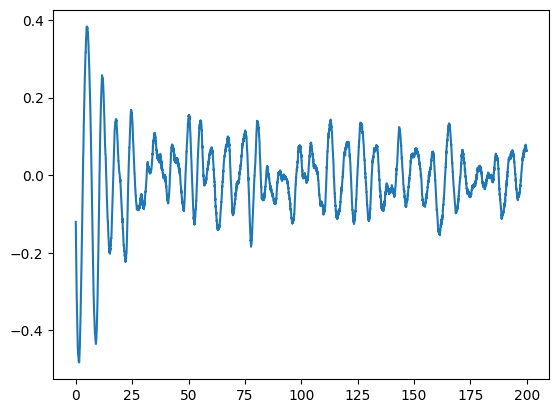

In [25]:
# linear approximation model
A = np.array([[0, 1], [-1, -0.3]])
B = np.array([[0], [1]])
C = np.array([[1, 0]])
D = np.array([[0]])

from scipy.integrate import solve_ivp

# simulate the linear approximation model using the inputs from the training data with rk45
def simulate_linear_model(x0, u, t):
    def dxdt(t, x):
        return A @ x + B @ u(t)
    sol = solve_ivp(dxdt, (t[0], t[-1]), x0, t_eval=t, method='RK45')
    return sol.y.T

u = data[0]['inputs'][0]
x0 = np.array([0, 0])
t = np.arange(len(u)) * 0.05  # assuming a sampling time of

y_hat = simulate_linear_model(x0, lambda t: u[int(t/0.05)], t)
fig, ax = plt.subplots()
ax.plot(t, data[0]['outputs'][0], label='Duffing output')

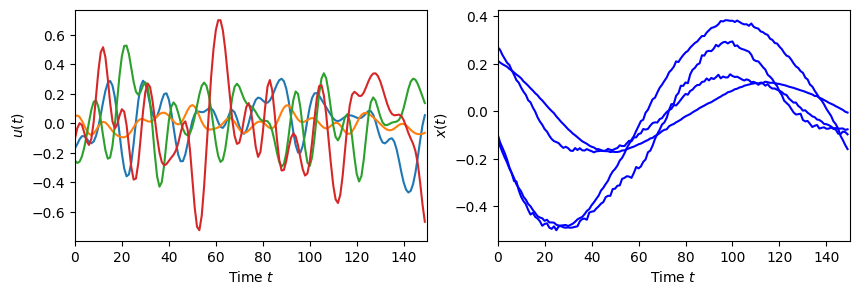

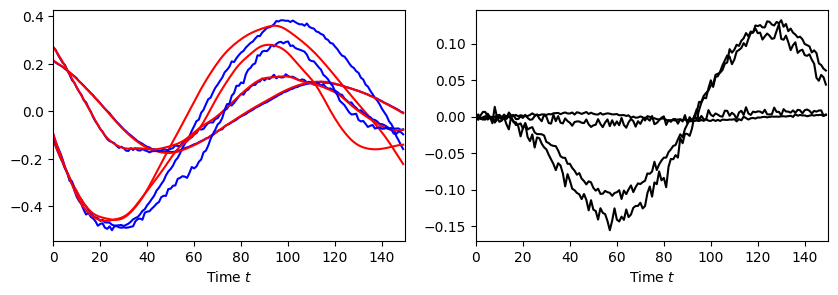

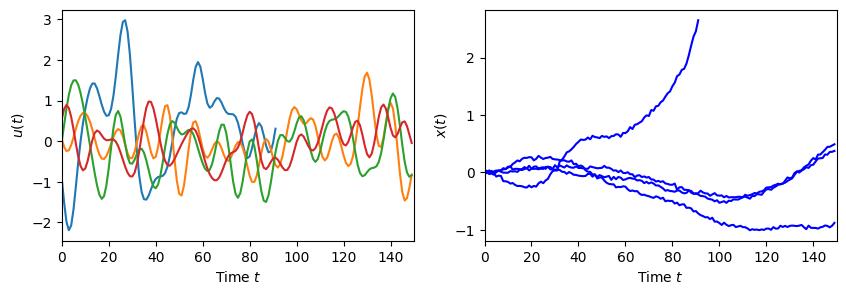

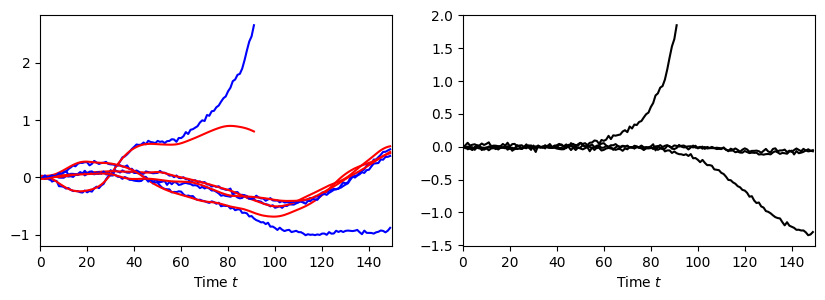

In [35]:
ts = 0.05

# print random 4 trajectories from each type
# all 4 input should be in one plot and all 4 output should be in another plot
N = 150

for d in data:
    y_hats = []
    fig, axs = plt.subplots(1, 2, figsize=(10, 3))
    fig2, axs2 = plt.subplots(1, 2, figsize=(10, 3))
    for i in range(4):
        if d['inputs'][i].shape[0] < N:
            axs[0].plot(d['inputs'][i], label=f'input {i}')
            u = d['inputs'][i]
        else:
            axs[0].plot(d['inputs'][i][:N], label=f'input {i}')
            u = d['inputs'][i][:N]
        t = np.arange(len(u)) * ts
        x0 = d['outputs'][i][0, :]
        y_hat = simulate_linear_model(x0, lambda t: u[int(t/ts)], t)
        y_hats.append(y_hat)
    axs[0].set_xlabel('Time $t$')
    axs[0].set_ylabel('$u(t)$')
    axs[0].set_xlim([0, 150])
    
    for i in range(4):
        if d['outputs'][i].shape[0] < N:
            axs[1].plot(d['outputs'][i][:,0], color='blue', label=f'output {i}')
            # axs[1].plot(y_hats[i][:, 0], color='red', label='linear approximation')
        else:
            axs[1].plot(d['outputs'][i][:N,0], color='blue', label=f'output {i}')
            # axs[1].plot(y_hats[i][:N, 0], color='red', label='linear approximation')
    axs[1].set_xlabel('Time $t$')
    axs[1].set_ylabel('$x(t)$')
    axs[1].set_xlim([0, 150])
    name = f"duffing_sample-input-output_{d['type:']}.tex"
    tikzplotlib.save(os.path.join(data_directory, name))

    for i in range(4):
        if d['outputs'][i].shape[0] < N:
            axs2[0].plot(d['outputs'][i][:,0], color='blue', label=f'output {i}')
            axs2[0].plot(y_hats[i][:, 0], color='red', label='linear approximation')
            e = d['outputs'][i][:,0] - y_hats[i][:, 0]
        else:
            axs2[0].plot(d['outputs'][i][:N,0], color='blue', label=f'output {i}')
            axs2[0].plot(y_hats[i][:N, 0], color='red', label='linear approximation')
            e = d['outputs'][i][:N,0] - y_hats[i][:N, 0]
        axs2[0].set_xlim([0, 150])
        axs2[0].set_xlabel('Time $t$')

        axs2[1].plot(e[:N], color='black', label=f'error {i}')
        axs2[1].set_xlim([0, 150])
        axs2[1].set_xlabel('Time $t$')

    name = f"duffing_linear_approximation-error_{d['type:']}.tex"
    tikzplotlib.save(os.path.join(data_directory, name))